# Principal Component Analysis (PCA) & Clustering on the Wine Dataset

**Objective:** Explore the 13 chemical measurements of Italian wines, reduce their dimensionality with PCA, and study how PCA affects K-means clustering compared with clustering on the original features.

**Dataset:** `wine.csv` – 178 wines from three cultivars (`Type` = 1, 2, 3) described by 13 chemical attributes.

**Important methodological note:** `Type` is the *known* cultivar label. It is **never** used to fit PCA or K-means (this is an unsupervised task). It is only used afterwards as an *external reference* to judge how well the discovered clusters match reality (Adjusted Rand Index, NMI, cross-tabulations).

| Task | Content |
|---|---|
| 1 | Exploratory Data Analysis |
| 2 | Dimensionality reduction with PCA |
| 3 | K-means on the original data |
| 4 | K-means on the PCA data |
| 5 | Comparison and analysis |
| 6 | Conclusion and insights |

In [1]:
# ---- Imports & global settings ----
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # reproducibility
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
PALETTE = {1: "#1b9e77", 2: "#d95f02", 3: "#7570b3"}   # one colour per wine type / cluster

---
## Task 1: Exploratory Data Analysis (EDA)
### 1.1 Load the data and basic exploration

In [2]:
df = pd.read_csv("wine.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (178, 14)


,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [3]:
# Data types, non-null counts, missing values and duplicates
df.info()
print("\nTotal missing values :", df.isna().sum().sum())
print("Duplicate rows       :", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Type             178 non-null    int64  
 1   Alcohol          178 non-null    float64
 2   Malic            178 non-null    float64
 3   Ash              178 non-null    float64
 4   Alcalinity       178 non-null    float64
 5   Magnesium        178 non-null    int64  
 6   Phenols          178 non-null    float64
 7   Flavanoids       178 non-null    float64
 8   Nonflavanoids    178 non-null    float64
 9   Proanthocyanins  178 non-null    float64
 10  Color            178 non-null    float64
 11  Hue              178 non-null    float64
 12  Dilution         178 non-null    float64
 13  Proline          178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB

Total missing values : 0
Duplicate rows       : 0


In [4]:
# Summary statistics of every feature
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Type,178.0,1.938,0.775,1.00,1.000,2.000,3.000,3.00
Alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
Malic,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
Ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
Alcalinity,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
Magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
Phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
Flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
Nonflavanoids,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
Proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58


Type
1    59
2    71
3    48
Name: count, dtype: int64


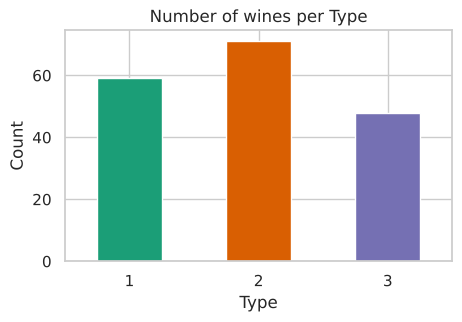

In [5]:
# Class balance of the (hidden) cultivar label
counts = df["Type"].value_counts().sort_index()
print(counts)
ax = counts.plot(kind="bar", color=[PALETTE[i] for i in counts.index], figsize=(5, 3))
ax.set_title("Number of wines per Type"); ax.set_xlabel("Type"); ax.set_ylabel("Count")
plt.xticks(rotation=0); plt.show()

**Observations**
- 178 observations and 13 numeric features plus the `Type` label; there are **no missing values and no duplicates**, so no cleaning or imputation is required.
- The classes are reasonably balanced (59 / 71 / 48), so clustering with k = 3 is a natural expectation.
- The features live on **very different scales** (e.g. `Proline` ≈ 278–1680, whereas `Hue` ≈ 0.5–1.7). This matters a lot for both PCA and K-means, which are distance/variance based, and motivates standardisation later on.

### 1.2 Distribution of the features

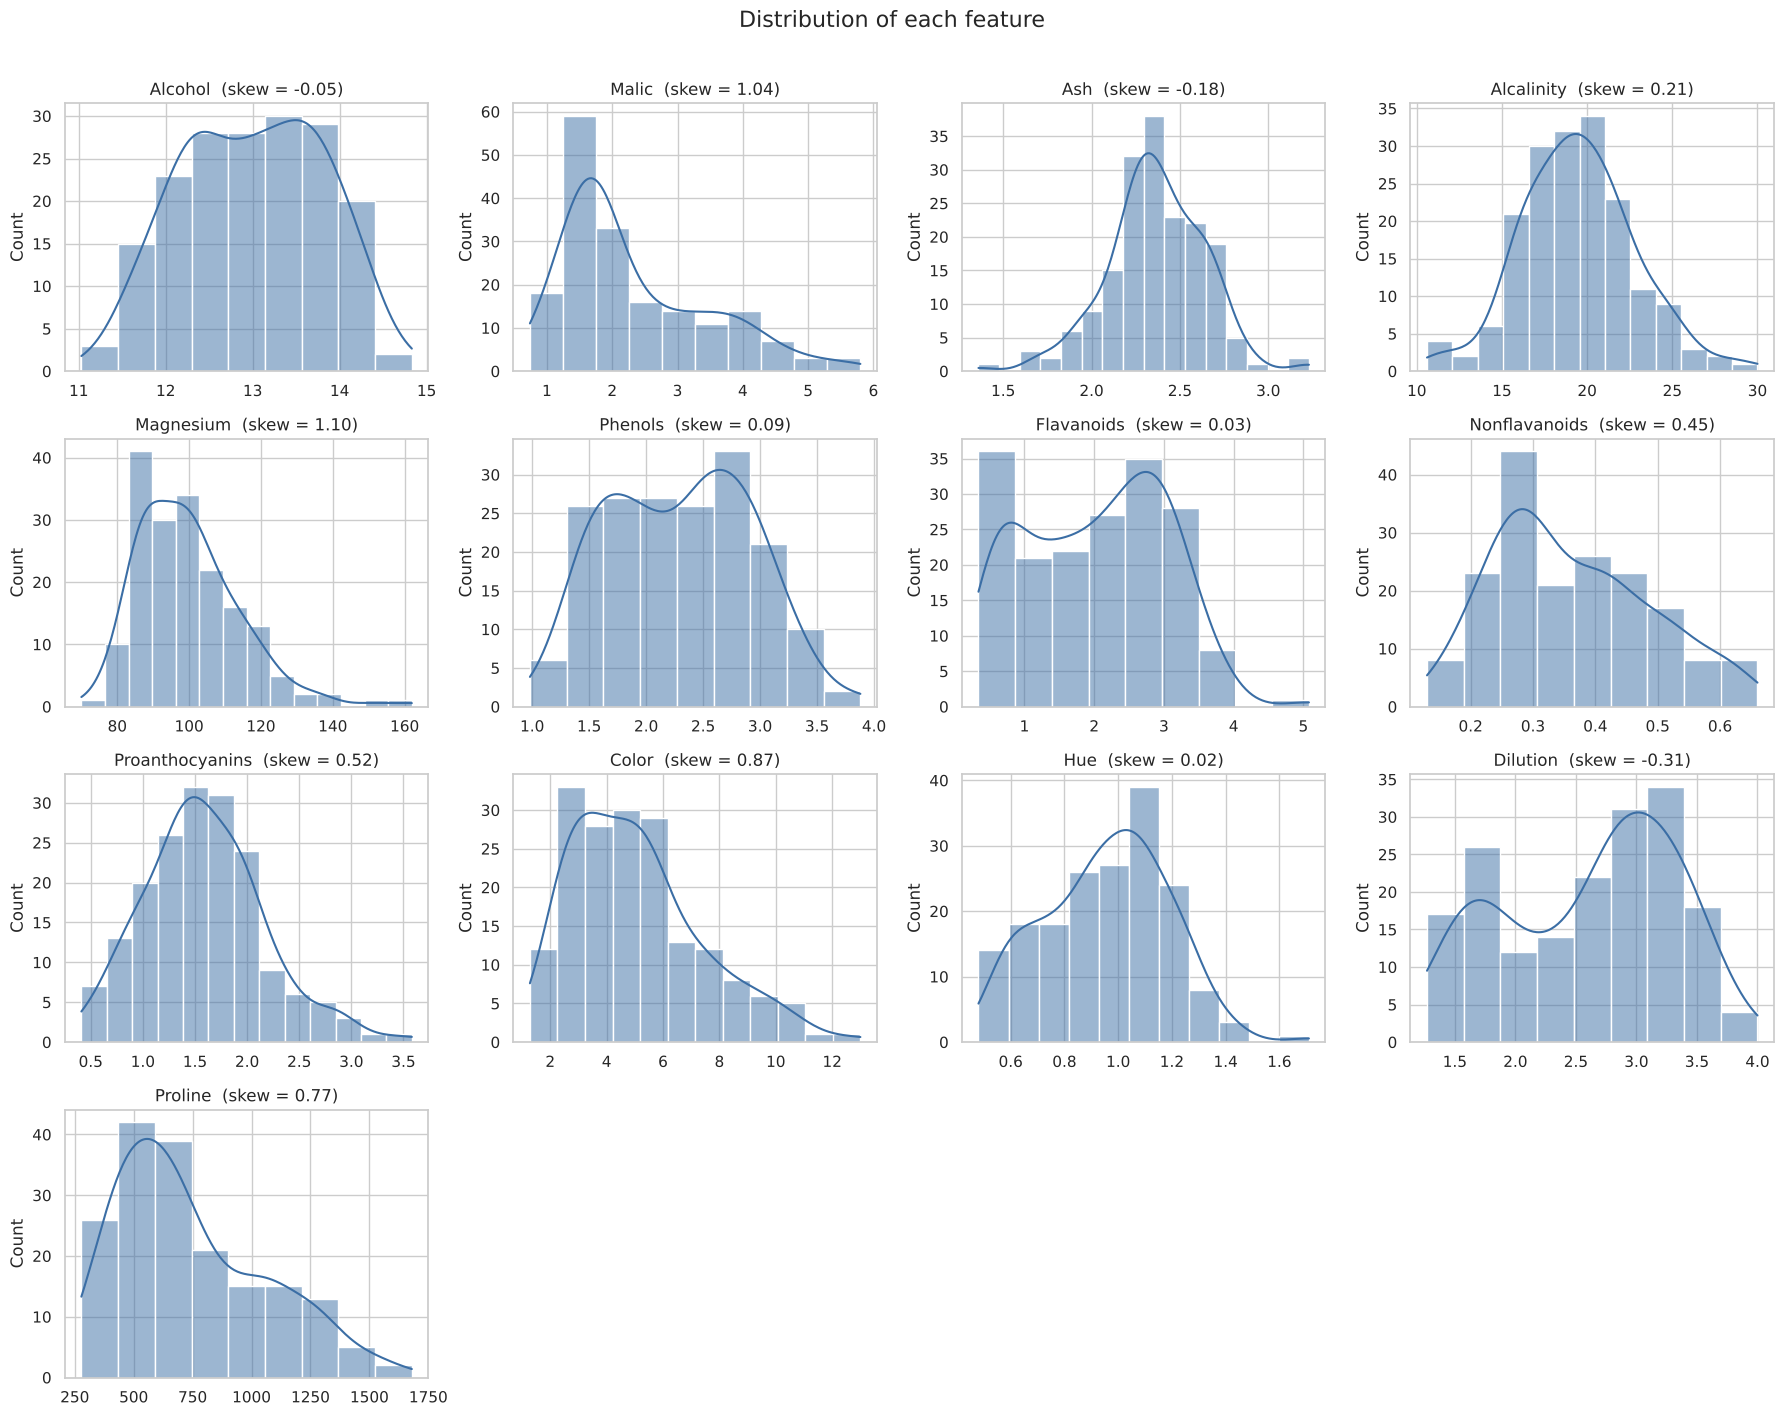

In [6]:
features = df.columns.drop("Type").tolist()      # the 13 chemical attributes
X = df[features]                                 # feature matrix (labels excluded)
y = df["Type"]                                   # reference labels (evaluation only)

# Histograms with a KDE (density) overlay
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], kde=True, ax=ax, color="#3b6ea5", edgecolor="white")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
    ax.set_xlabel("")
for ax in axes.ravel()[len(features):]:
    ax.axis("off")                               # hide unused sub-plots
plt.suptitle("Distribution of each feature", fontsize=16, y=1.01)
plt.tight_layout(); plt.show()

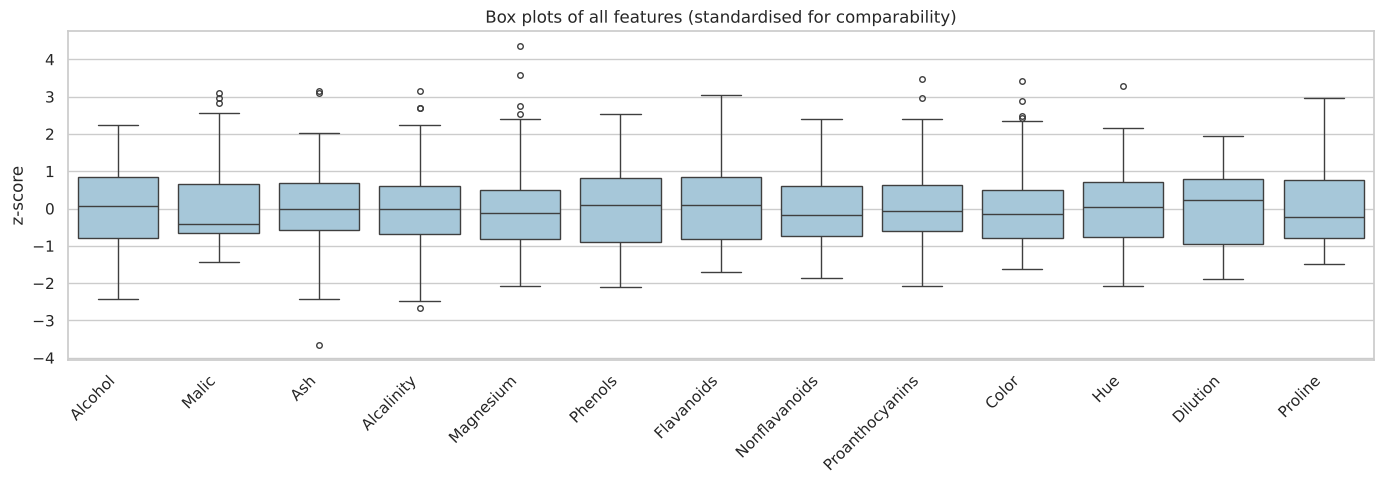

Outliers per feature (1.5*IQR rule):
Alcalinity         4
Color              4
Magnesium          4
Ash                3
Malic              3
Proanthocyanins    2
Hue                1


In [7]:
# Box plots on standardised values so that all 13 features share one axis and outliers are comparable
X_std_view = (X - X.mean()) / X.std()
plt.figure(figsize=(14, 5))
sns.boxplot(data=X_std_view, color="#9ecae1", fliersize=4)
plt.xticks(rotation=45, ha="right")
plt.ylabel("z-score"); plt.title("Box plots of all features (standardised for comparability)")
plt.tight_layout(); plt.show()

# Number of outliers per feature using the 1.5 x IQR rule
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
outliers = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum()
print("Outliers per feature (1.5*IQR rule):")
print(outliers[outliers > 0].sort_values(ascending=False).to_string())

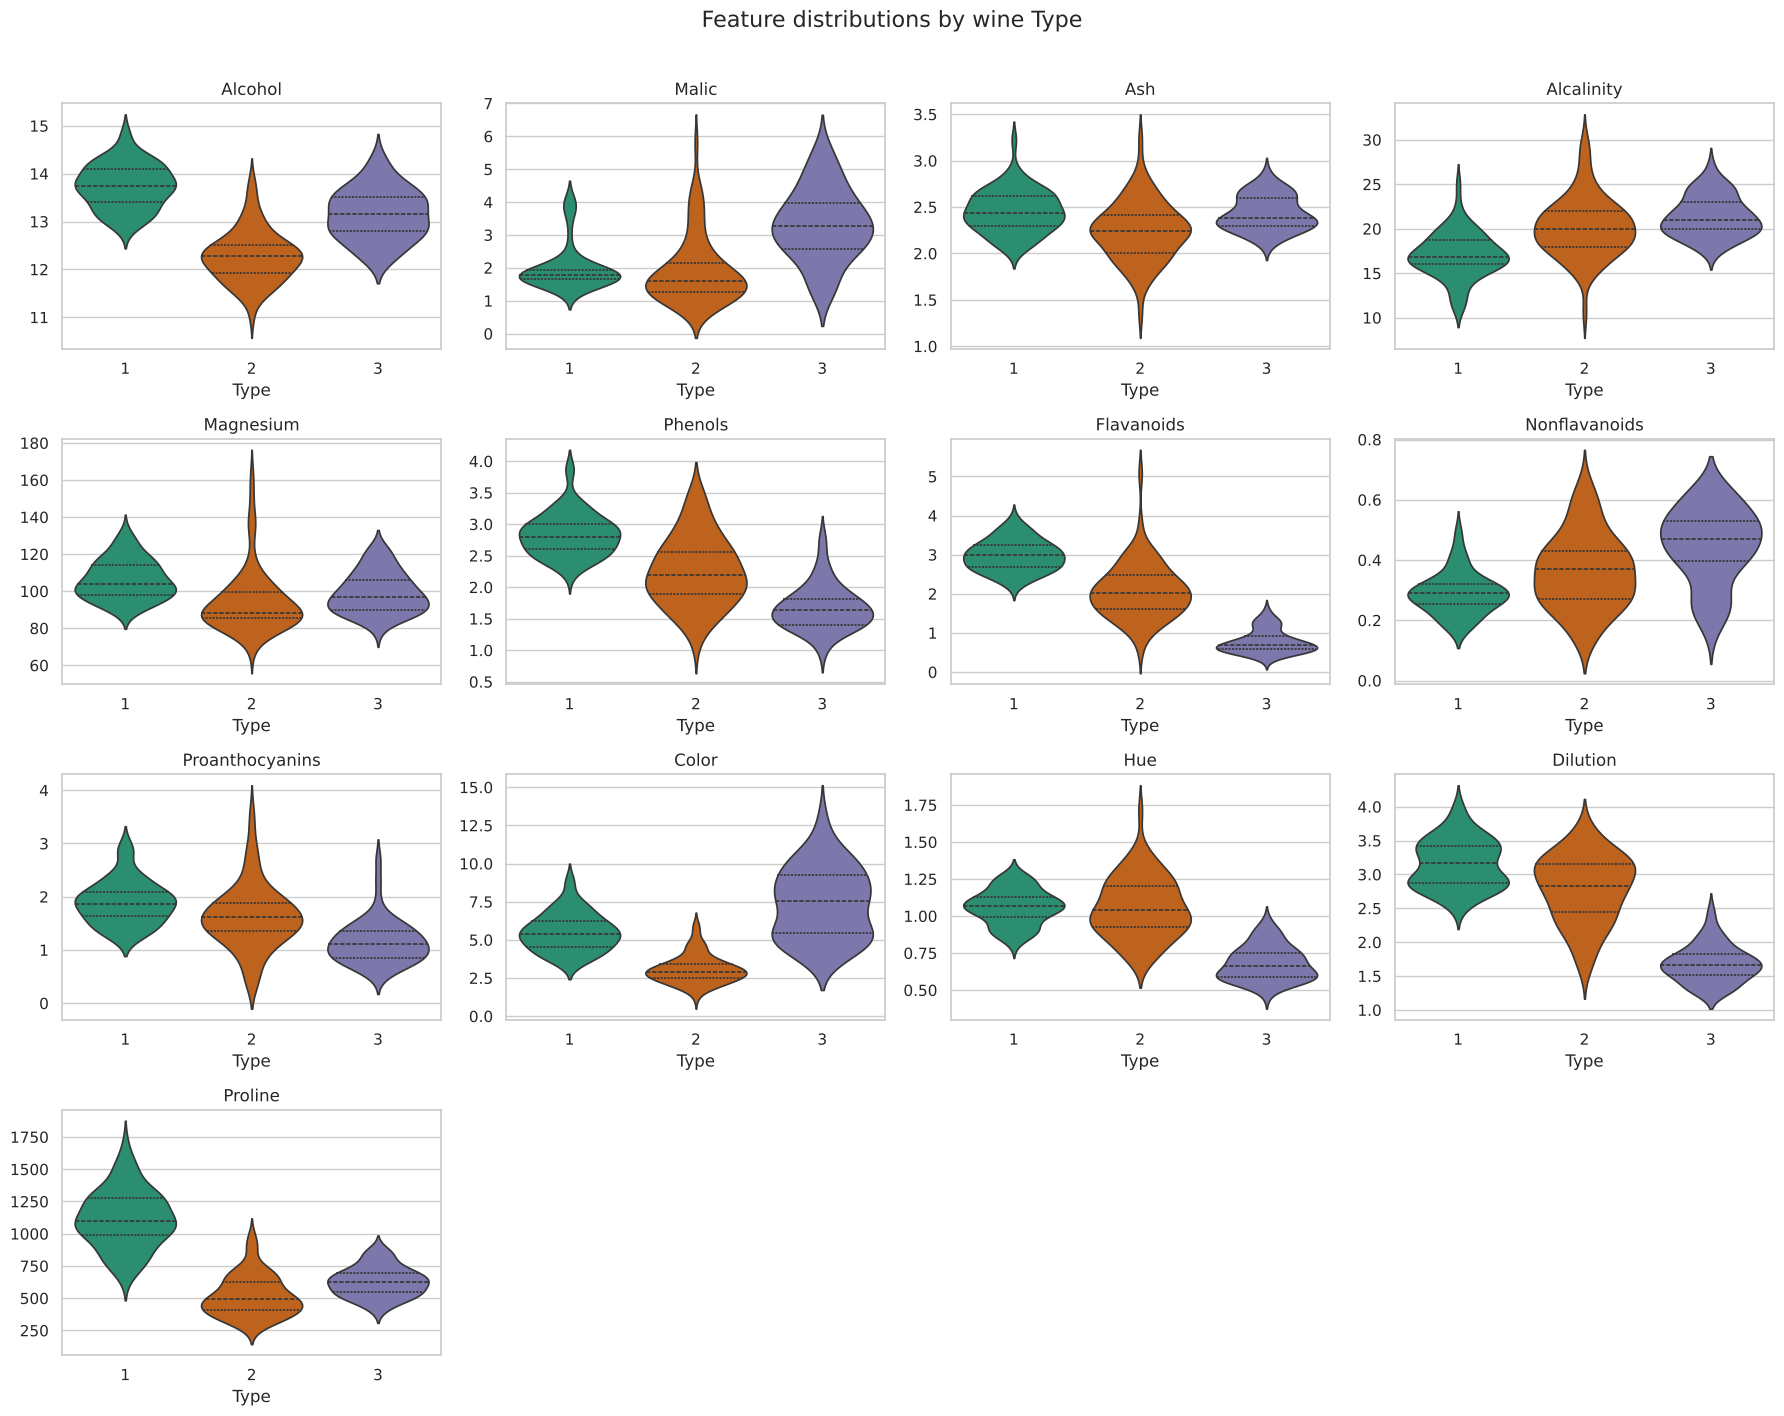

In [8]:
# How do the features differ between wine types? (violin plots, one panel per feature)
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), features):
    sns.violinplot(data=df, x="Type", y=col, hue="Type", palette=list(PALETTE.values()), legend=False, ax=ax, inner="quartile")
    ax.set_title(col); ax.set_xlabel("Type"); ax.set_ylabel("")
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
plt.suptitle("Feature distributions by wine Type", fontsize=16, y=1.01)
plt.tight_layout(); plt.show()

**Observations**
- Most features are roughly bell-shaped. `Malic`, `Magnesium`, `Color`, `Proline` and `Proanthocyanins` are right-skewed, and a handful of features (`Alcalinity`, `Color`, `Magnesium`, `Ash`, `Malic`) have 3–4 mild outliers each; the outliers are plausible chemical measurements, so they are **kept**.
- Several features separate the wine types visibly: `Flavanoids`, `Phenols`, `Dilution` and `Hue` are low for Type 3, `Proline` and `Alcohol` are high for Type 1, and `Color` is highest for Type 3 – so the cultivars have a genuine chemical signature that clustering could recover.

### 1.3 Correlations between features

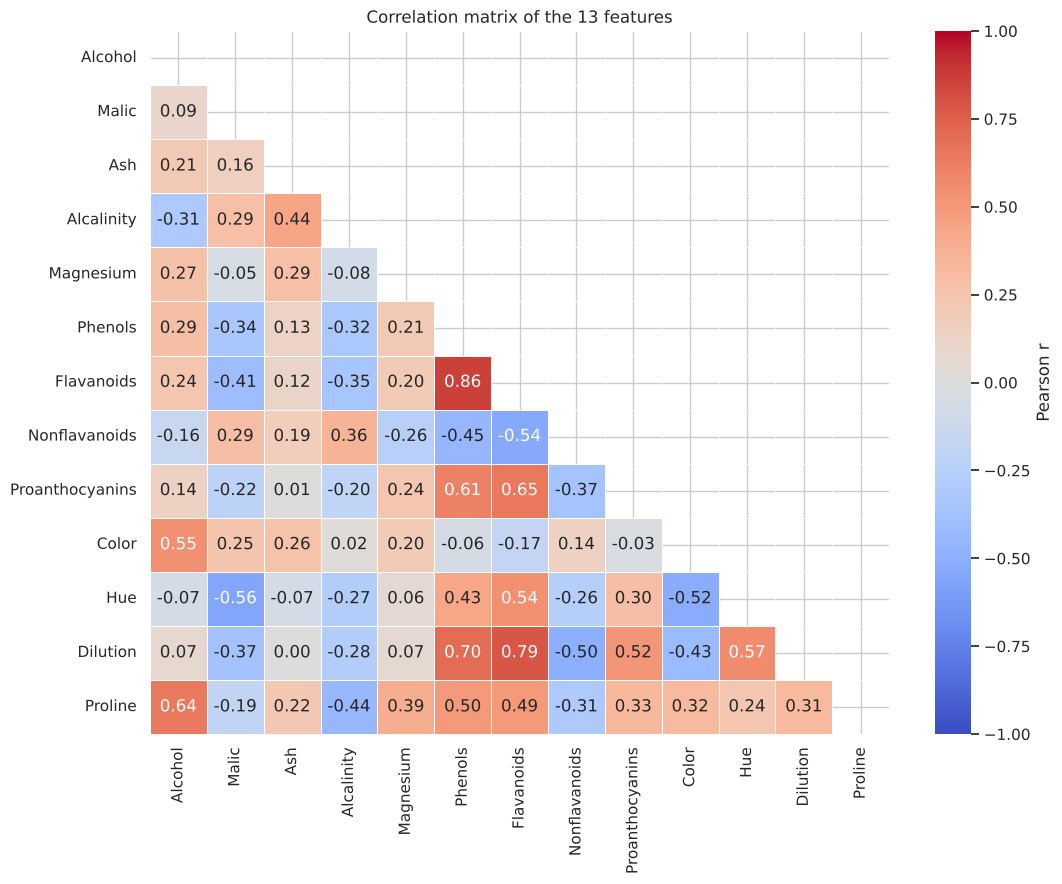

Top 8 correlated feature pairs:


,Feature A,Feature B,r
0,Flavanoids,Phenols,0.865
1,Dilution,Flavanoids,0.787
2,Dilution,Phenols,0.700
3,Proanthocyanins,Flavanoids,0.653
4,Proline,Alcohol,0.644
5,Proanthocyanins,Phenols,0.612
6,Dilution,Hue,0.565
7,Hue,Malic,-0.561


In [9]:
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))          # show only the lower triangle
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Pearson r"})
plt.title("Correlation matrix of the 13 features"); plt.tight_layout(); plt.show()

# Strongest pairwise relationships
pairs = (corr.where(~mask).stack().rename("r").reset_index()
             .rename(columns={"level_0": "Feature A", "level_1": "Feature B"}))
pairs["|r|"] = pairs["r"].abs()
print("Top 8 correlated feature pairs:")
pairs.sort_values("|r|", ascending=False).head(8).drop(columns="|r|").round(3).reset_index(drop=True)

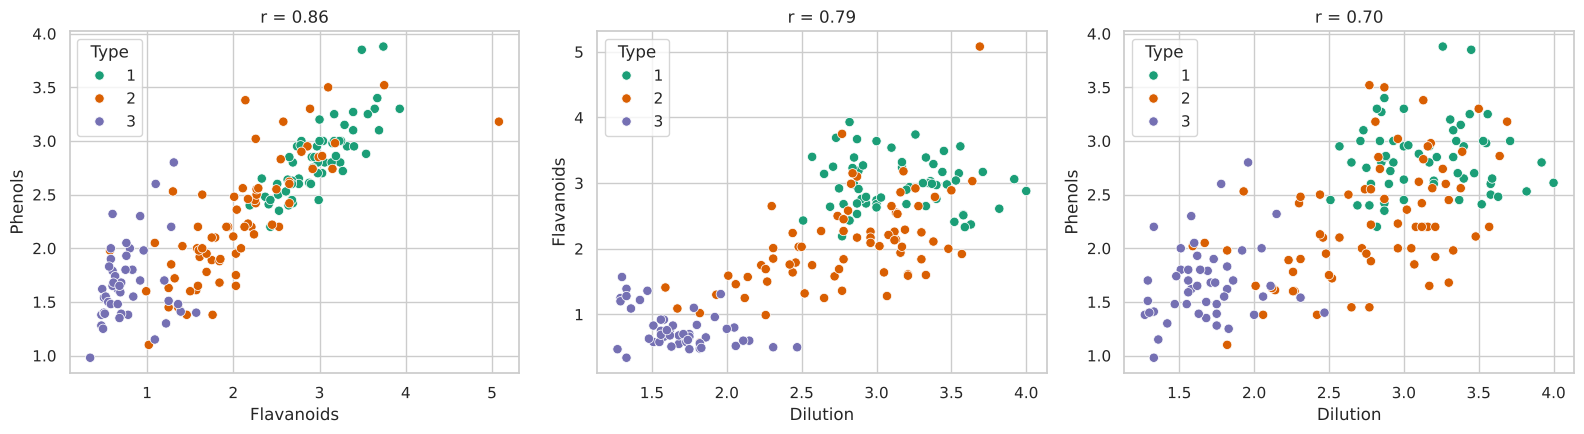

In [10]:
# Scatter plots of the most strongly related pairs, coloured by wine type
top = pairs.sort_values("|r|", ascending=False).head(3)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (_, row) in zip(axes, top.iterrows()):
    sns.scatterplot(data=df, x=row["Feature A"], y=row["Feature B"], hue="Type",
                    palette=PALETTE, ax=ax, s=45, edgecolor="white")
    ax.set_title(f"r = {row['r']:.2f}")
plt.tight_layout(); plt.show()

**Observations**
- There is clear **multicollinearity**: `Flavanoids` – `Phenols` (r ≈ 0.86), `Flavanoids` – `Dilution` (r ≈ 0.79), `Flavanoids` – `Proanthocyanins` (r ≈ 0.65) and `Phenols` – `Dilution` form a block of strongly correlated "phenolic" variables, while `Malic` is negatively correlated with `Hue` (r ≈ –0.56).
- Redundant, correlated variables carry overlapping information – exactly the situation in which PCA can compress the data into fewer uncorrelated components with little loss.

---
## Task 2: Dimensionality Reduction with PCA
### 2.1 Standardise the features
PCA finds the directions of maximum **variance**. Without scaling, large-valued features such as `Proline` (variance ≈ 99,000) would swamp small-valued ones such as `Hue` (variance ≈ 0.05) and dominate every component. We therefore standardise each feature to **mean 0 and standard deviation 1** (z-score).

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)                       # (x - mean) / std for every feature
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

# Verify the standardisation
check = pd.DataFrame({"mean": X_scaled_df.mean().round(6), "std": X_scaled_df.std(ddof=0).round(6)})
check.T

,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
mean,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 2.2 Fit PCA with all components
We first keep all 13 components to inspect how much variance each of them explains.

In [12]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)

var_table = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, 14)],
    "Eigenvalue": pca_full.explained_variance_,
    "Explained variance (%)": pca_full.explained_variance_ratio_ * 100,
    "Cumulative variance (%)": np.cumsum(pca_full.explained_variance_ratio_) * 100,
}).set_index("PC")
var_table.round(2)

,Eigenvalue,Explained variance (%),Cumulative variance (%)
PC,,,
PC1,4.73,36.20,36.20
PC2,2.51,19.21,55.41
PC3,1.45,11.12,66.53
PC4,0.92,7.07,73.60
PC5,0.86,6.56,80.16
PC6,0.65,4.94,85.10
PC7,0.55,4.24,89.34
PC8,0.35,2.68,92.02
PC9,0.29,2.22,94.24


### 2.3 Choosing the number of components (scree plot & cumulative explained variance)

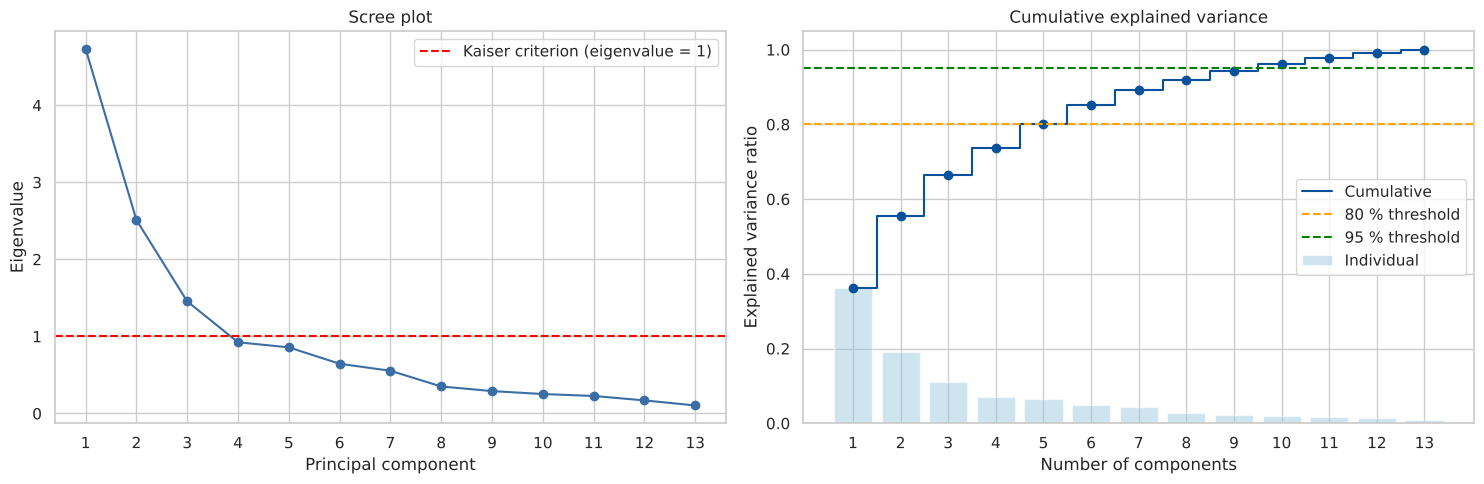

Kaiser criterion (eigenvalue > 1) : 3 components  (66.5% of variance)
≥ 80 % of the variance            : 5 components  (80.2%)
≥ 95 % of the variance            : 10 components  (96.2%)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pcs = np.arange(1, 14)

# (a) Scree plot with the Kaiser criterion (eigenvalue > 1)
axes[0].plot(pcs, pca_full.explained_variance_, "o-", color="#3b6ea5")
axes[0].axhline(1, color="red", ls="--", label="Kaiser criterion (eigenvalue = 1)")
axes[0].set_xticks(pcs); axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Eigenvalue")
axes[0].set_title("Scree plot"); axes[0].legend()

# (b) Cumulative explained variance with 80 % / 95 % guide lines
cum = np.cumsum(pca_full.explained_variance_ratio_)
axes[1].bar(pcs, pca_full.explained_variance_ratio_, alpha=.5, label="Individual", color="#9ecae1")
axes[1].step(pcs, cum, where="mid", color="#08519c", label="Cumulative")
axes[1].plot(pcs, cum, "o", color="#08519c")
for thr, c in [(0.80, "orange"), (0.95, "green")]:
    axes[1].axhline(thr, color=c, ls="--", label=f"{int(thr*100)} % threshold")
axes[1].set_xticks(pcs); axes[1].set_xlabel("Number of components"); axes[1].set_ylabel("Explained variance ratio")
axes[1].set_title("Cumulative explained variance"); axes[1].legend(loc="center right")
plt.tight_layout(); plt.show()

n_kaiser = int((pca_full.explained_variance_ > 1).sum())
n_80 = int(np.argmax(cum >= 0.80) + 1)
n_95 = int(np.argmax(cum >= 0.95) + 1)
print(f"Kaiser criterion (eigenvalue > 1) : {n_kaiser} components  ({cum[n_kaiser-1]:.1%} of variance)")
print(f"≥ 80 % of the variance            : {n_80} components  ({cum[n_80-1]:.1%})")
print(f"≥ 95 % of the variance            : {n_95} components  ({cum[n_95-1]:.1%})")

**Decision.** The three criteria give different answers:

| Criterion | # PCs | Variance kept |
|---|---|---|
| Scree "elbow" / Kaiser (eigenvalue > 1) | 3 | 66.5 % |
| ≥ 80 % cumulative variance | **5** | 80.2 % |
| ≥ 95 % cumulative variance | 10 | 96.2 % |

The scree plot bends sharply after PC3, and the Kaiser rule is the most aggressive. Because 3 components discard a third of the information, we adopt the common **80 % rule and keep 5 components** as the main PCA representation (a reduction from 13 to 5 dimensions, i.e. –62 %). In addition, we use the **first 2 components** (55.4 % of the variance) purely for 2-D visualisation. Later on we also check how sensitive the clustering is to this choice.

### 2.4 Transform the data into principal components

In [14]:
N_COMPONENTS = 5                                     # chosen in section 2.3
pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)                  # 178 x 5 matrix of PC scores

pc_cols = [f"PC{i}" for i in range(1, N_COMPONENTS + 1)]
X_pca_df = pd.DataFrame(X_pca, columns=pc_cols)
print("Original shape :", X_scaled.shape)
print("PCA shape      :", X_pca.shape)
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.2%}")
display(X_pca_df.head())

# The components are uncorrelated by construction -> correlation matrix ≈ identity
print("Max |off-diagonal correlation| between PCs:",
      np.abs(np.corrcoef(X_pca.T) - np.eye(N_COMPONENTS)).max().round(10))

Original shape : (178, 13)
PCA shape      : (178, 5)
Variance retained: 80.16%


,PC1,PC2,PC3,PC4,PC5
0,3.316751,1.443463,-0.165739,-0.215631,0.693043
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655
2,2.516740,1.031151,0.982819,0.724902,-0.251033
3,3.757066,2.756372,-0.176192,0.567983,-0.311842
4,1.008908,0.869831,2.026688,-0.409766,0.298458


Max |off-diagonal correlation| between PCs: 0.0


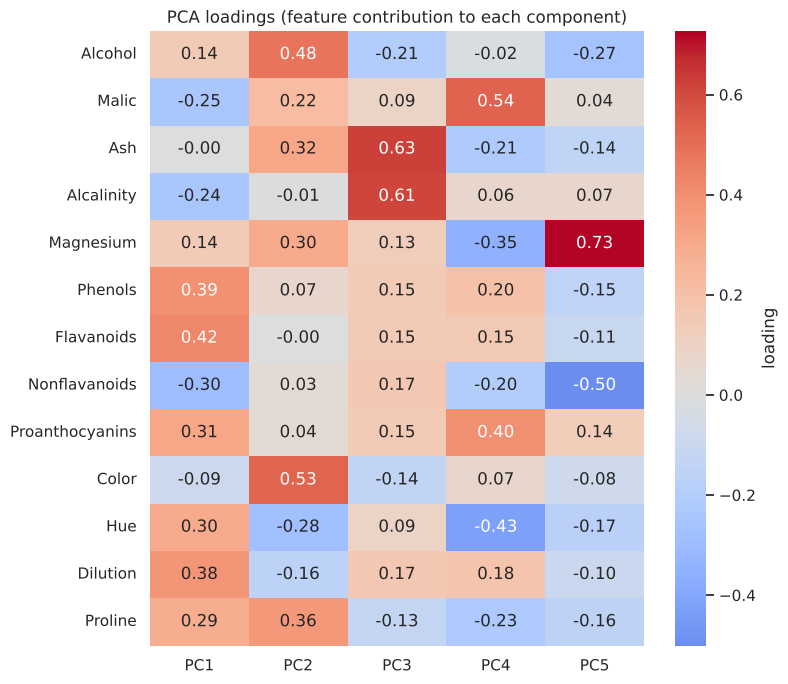

In [15]:
# Loadings: how much each original feature contributes to each component
loadings = pd.DataFrame(pca.components_.T, index=features, columns=pc_cols)
plt.figure(figsize=(8, 7))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"label": "loading"})
plt.title("PCA loadings (feature contribution to each component)")
plt.tight_layout(); plt.show()

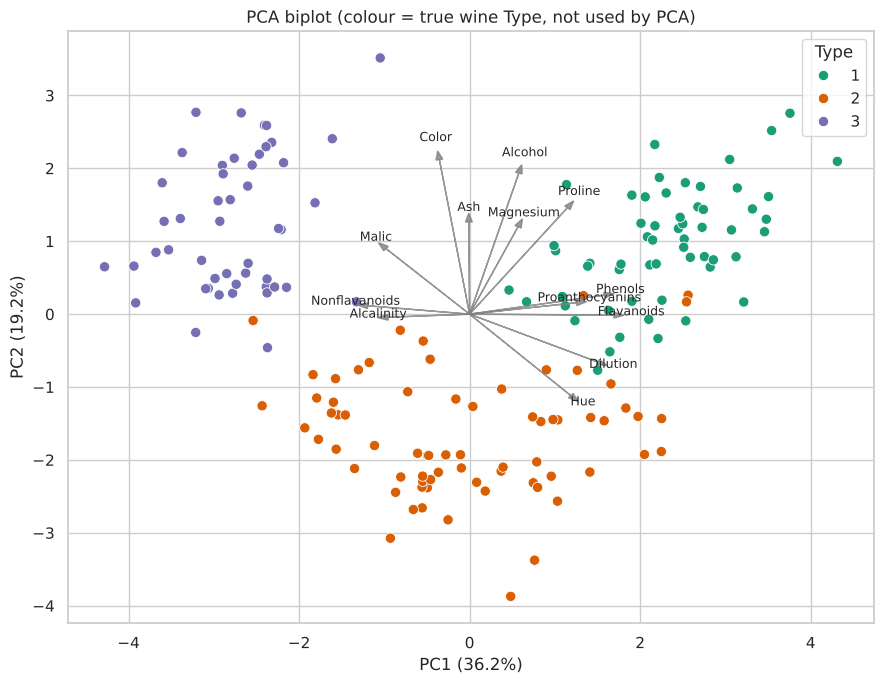

In [16]:
# Biplot: first two components, samples coloured by type, arrows = feature loadings
scores2 = X_pca[:, :2]
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(x=scores2[:, 0], y=scores2[:, 1], hue=y, palette=PALETTE, s=55, edgecolor="white", ax=ax)
scale = 4.0                                          # arrow length scaling for readability
for feat, (lx, ly) in zip(features, loadings[["PC1", "PC2"]].values):
    ax.arrow(0, 0, lx * scale, ly * scale, color="gray", alpha=.8, head_width=0.08)
    ax.text(lx * scale * 1.12, ly * scale * 1.12, feat, fontsize=9, ha="center")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA biplot (colour = true wine Type, not used by PCA)")
ax.legend(title="Type"); plt.tight_layout(); plt.show()

**Interpretation of the components**
- **PC1 (36.2 %)** is driven positively by `Flavanoids`, `Phenols`, `Dilution`, `Proanthocyanins` and `Hue`, and negatively by `Nonflavanoids`, `Malic` and `Alcalinity` – a "phenolic content / wine quality" axis.
- **PC2 (19.2 %)** is driven mainly by `Color`, `Alcohol` and `Proline` – a "colour intensity / alcohol strength" axis.
- Even with the labels hidden, the first two components already place the three wine types in three largely separate regions, indicating that PCA has preserved the structure that matters for clustering.

---
## Task 3: Clustering with the Original Data
We use **K-means** (k = 3, `n_init = 20` random restarts for stability).

"Original data" can be understood in two ways, so we evaluate both:
1. **Raw original features** – exactly as measured (unscaled);
2. **Standardised original features** – all 13 features, scaled to z-scores (this is the fair "full-dimensional" baseline for PCA, since PCA itself was run on standardised data).

### 3.1 Choosing k (elbow method and silhouette analysis)

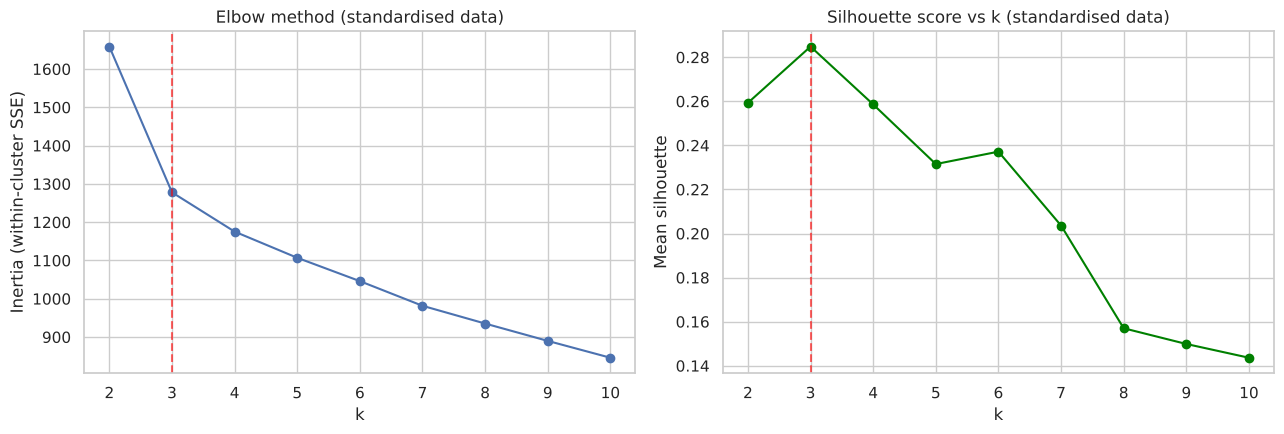

Best k by silhouette: 3


In [17]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, inertia, "o-"); axes[0].set_title("Elbow method (standardised data)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[1].plot(ks, sil, "o-", color="green"); axes[1].set_title("Silhouette score vs k (standardised data)")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Mean silhouette")
for a in axes: a.axvline(3, color="red", ls="--", alpha=.6)
plt.tight_layout(); plt.show()
print("Best k by silhouette:", list(ks)[int(np.argmax(sil))])

Both plots support **k = 3**: the elbow is at k = 3 and the silhouette score is highest there. This also agrees with the three known cultivars. We use k = 3 throughout.

### 3.2 K-means on the raw (unscaled) and standardised original data

In [18]:
def run_kmeans(data, k=3):
    """Fit K-means and return (labels, fitted model, fit time in seconds)."""
    t0 = time.perf_counter()
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(data)
    return km.labels_, km, time.perf_counter() - t0

def evaluate(data, labels, true_labels=y):
    """Internal metrics (use only data + labels) and external metrics (compare with true Type)."""
    return {
        "Silhouette (↑)": silhouette_score(data, labels),
        "Davies-Bouldin (↓)": davies_bouldin_score(data, labels),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(data, labels),
        "Adjusted Rand Index (↑)": adjusted_rand_score(true_labels, labels),
        "Normalised Mutual Info (↑)": normalized_mutual_info_score(true_labels, labels),
    }

labels_raw, km_raw, t_raw = run_kmeans(X.values)       # raw original features
labels_std, km_std, t_std = run_kmeans(X_scaled)       # standardised original features

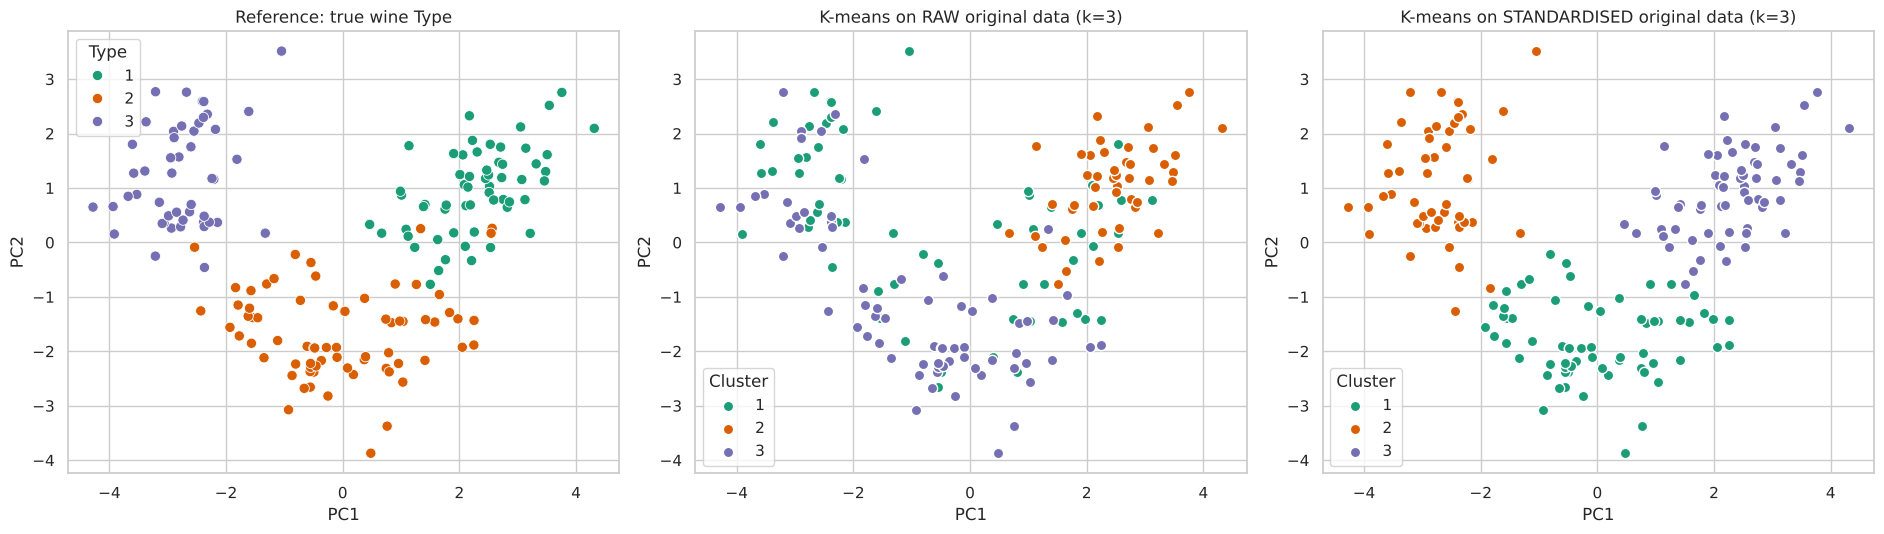

In [19]:
# Visualise both solutions in the same 2-D PCA projection (PC1 vs PC2) so they are easy to compare
def plot_clusters(ax, coords, labels, title):
    for c in np.unique(labels):
        m = labels == c
        ax.scatter(coords[m, 0], coords[m, 1], color=PALETTE[c + 1], s=55, edgecolor="white", label=str(c + 1))
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(title="Cluster")

pc2 = X_pca[:, :2]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
sns.scatterplot(x=pc2[:, 0], y=pc2[:, 1], hue=y, palette=PALETTE, s=55, edgecolor="white", ax=axes[0])
axes[0].set_title("Reference: true wine Type"); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plot_clusters(axes[1], pc2, labels_raw, "K-means on RAW original data (k=3)")
plot_clusters(axes[2], pc2, labels_std, "K-means on STANDARDISED original data (k=3)")
plt.tight_layout(); plt.show()

In [20]:
# Cross-tabulation of clusters against true types (cluster numbering is arbitrary)
print("RAW original data – clusters vs true Type")
display(pd.crosstab(labels_raw + 1, y, rownames=["Cluster"], colnames=["Type"]))
print("STANDARDISED original data – clusters vs true Type")
display(pd.crosstab(labels_std + 1, y, rownames=["Cluster"], colnames=["Type"]))

RAW original data – clusters vs true Type


Type,1,2,3
Cluster,,,
1,13,20,29
2,46,1,0
3,0,50,19


STANDARDISED original data – clusters vs true Type


Type,1,2,3
Cluster,,,
1,0,65,0
2,0,3,48
3,59,3,0


In [21]:
# Why does the raw data behave so differently? Look at the variance of each raw feature
raw_var = X.var().sort_values(ascending=False)
print("Variance of raw features (top 5):")
print(raw_var.head(5).round(2).to_string())
print(f"\nProline alone accounts for {raw_var['Proline'] / raw_var.sum():.2%} of total raw variance")

Variance of raw features (top 5):
Proline       99166.72
Magnesium       203.99
Alcalinity       11.15
Color             5.37
Malic             1.25

Proline alone accounts for 99.77% of total raw variance


Without scaling, K-means is essentially clustering on **`Proline` alone** – it has a variance of ~99,000 (99.8 % of the total raw variance) versus < 1 for most other features. The result looks compact (high silhouette) but it ignores almost all of the chemistry and mixes the wine types (see cross-tab). Scaling is therefore essential and the standardised version is our proper baseline.

### 3.3 Evaluation of clustering on the original data

In [22]:
results = {
    "Original – raw (13D)":          evaluate(X.values, labels_raw),
    "Original – standardised (13D)": evaluate(X_scaled, labels_std),
}
pd.DataFrame(results).T.round(3)

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Adjusted Rand Index (↑),Normalised Mutual Info (↑)
Original – raw (13D),0.571,0.534,561.816,0.371,0.429
Original – standardised (13D),0.285,1.389,70.940,0.897,0.876


- **Raw data:** the *internal* metrics look very good (silhouette ≈ 0.57, Davies-Bouldin ≈ 0.53) but the *external* agreement with the real cultivars is poor (ARI ≈ 0.37). The metrics reward compact clusters along a single dominant feature, **not** meaningful structure – a good reminder that internal indices must be interpreted with care.
- **Standardised data:** the internal scores are lower (silhouette ≈ 0.28, DB ≈ 1.39) because the 13-D space is noisier, yet the clusters recover the true cultivars far better (ARI ≈ 0.90).

---
## Task 4: Clustering with PCA Data
We apply the **same algorithm and settings** (K-means, k = 3, `n_init = 20`, same seed) to the PCA-transformed data with the 5 retained components.

In [23]:
labels_pca, km_pca, t_pca = run_kmeans(X_pca)          # 5 principal components
labels_pca2, km_pca2, t_pca2 = run_kmeans(X_pca[:, :2])  # 2 PCs (visualisation variant)

print("Cluster sizes (PCA, 5 PCs):", np.bincount(labels_pca))

Cluster sizes (PCA, 5 PCs): [65 51 62]


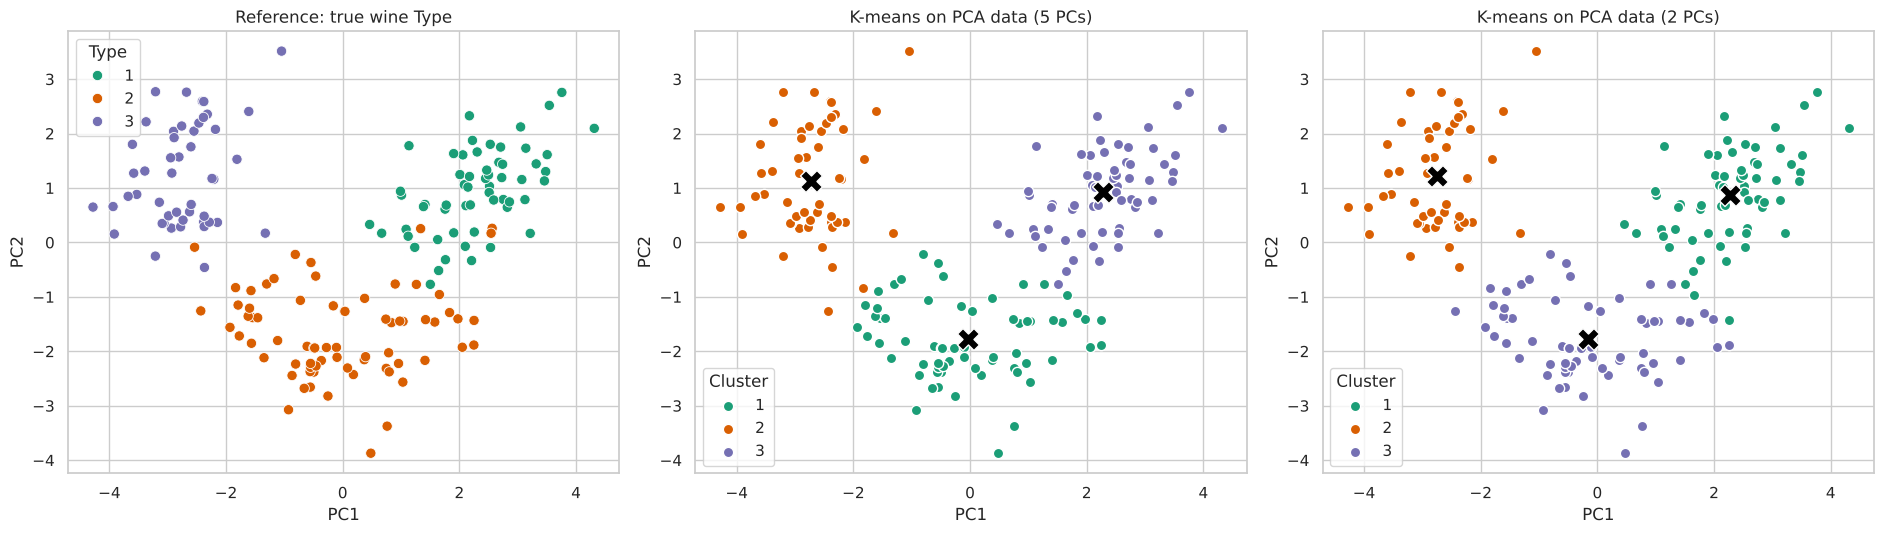

In [24]:
# Visualise the PCA-based clusters, with the centroids projected onto PC1/PC2
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
sns.scatterplot(x=pc2[:, 0], y=pc2[:, 1], hue=y, palette=PALETTE, s=55, edgecolor="white", ax=axes[0])
axes[0].set_title("Reference: true wine Type"); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

plot_clusters(axes[1], pc2, labels_pca, f"K-means on PCA data ({N_COMPONENTS} PCs)")
axes[1].scatter(km_pca.cluster_centers_[:, 0], km_pca.cluster_centers_[:, 1],
                marker="X", s=250, c="black", edgecolor="white", label="Centroids")

plot_clusters(axes[2], pc2, labels_pca2, "K-means on PCA data (2 PCs)")
axes[2].scatter(km_pca2.cluster_centers_[:, 0], km_pca2.cluster_centers_[:, 1],
                marker="X", s=250, c="black", edgecolor="white")
plt.tight_layout(); plt.show()

In [25]:
print("PCA data (5 PCs) – clusters vs true Type")
display(pd.crosstab(labels_pca + 1, y, rownames=["Cluster"], colnames=["Type"]))
print("PCA data (2 PCs) – clusters vs true Type")
display(pd.crosstab(labels_pca2 + 1, y, rownames=["Cluster"], colnames=["Type"]))

PCA data (5 PCs) – clusters vs true Type


Type,1,2,3
Cluster,,,
1,0,65,0
2,0,3,48
3,59,3,0


PCA data (2 PCs) – clusters vs true Type


Type,1,2,3
Cluster,,,
1,59,5,0
2,0,1,48
3,0,65,0


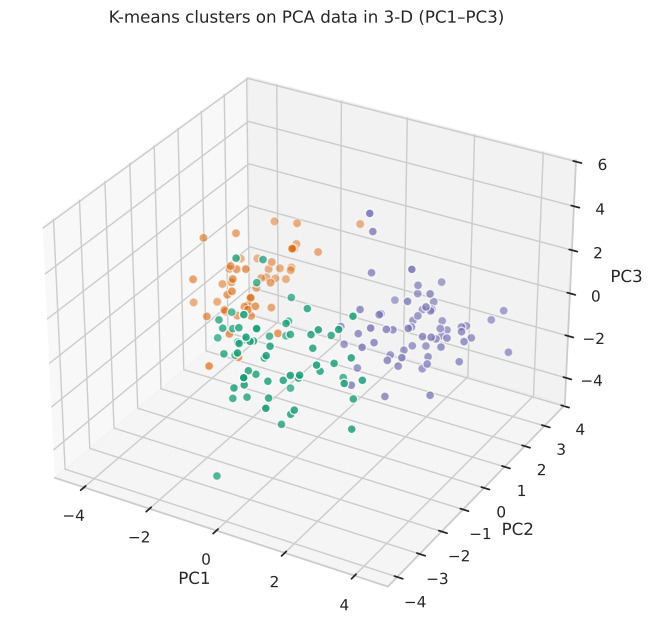

In [26]:
# 3-D view of the first three components for a richer picture
fig = plt.figure(figsize=(8, 6.5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=[PALETTE[l + 1] for l in labels_pca], s=40, edgecolor="white")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("K-means clusters on PCA data in 3-D (PC1–PC3)")
plt.tight_layout(); plt.show()

### 4.1 Comparison of the PCA-based clustering with the original-data clustering

In [27]:
results["PCA – 5 PCs"] = evaluate(X_pca, labels_pca)
results["PCA – 2 PCs"] = evaluate(X_pca[:, :2], labels_pca2)
comparison = pd.DataFrame(results).T
comparison["Dimensions"] = [13, 13, 5, 2]
comparison["Fit time (ms)"] = np.array([t_raw, t_std, t_pca, t_pca2]) * 1000
comparison.round(3)

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Adjusted Rand Index (↑),Normalised Mutual Info (↑),Dimensions,Fit time (ms)
Original – raw (13D),0.571,0.534,561.816,0.371,0.429,13,17.855
Original – standardised (13D),0.285,1.389,70.940,0.897,0.876,13,23.678
PCA – 5 PCs,0.369,1.093,109.233,0.897,0.876,5,17.635
PCA – 2 PCs,0.561,0.597,344.793,0.895,0.882,2,13.059


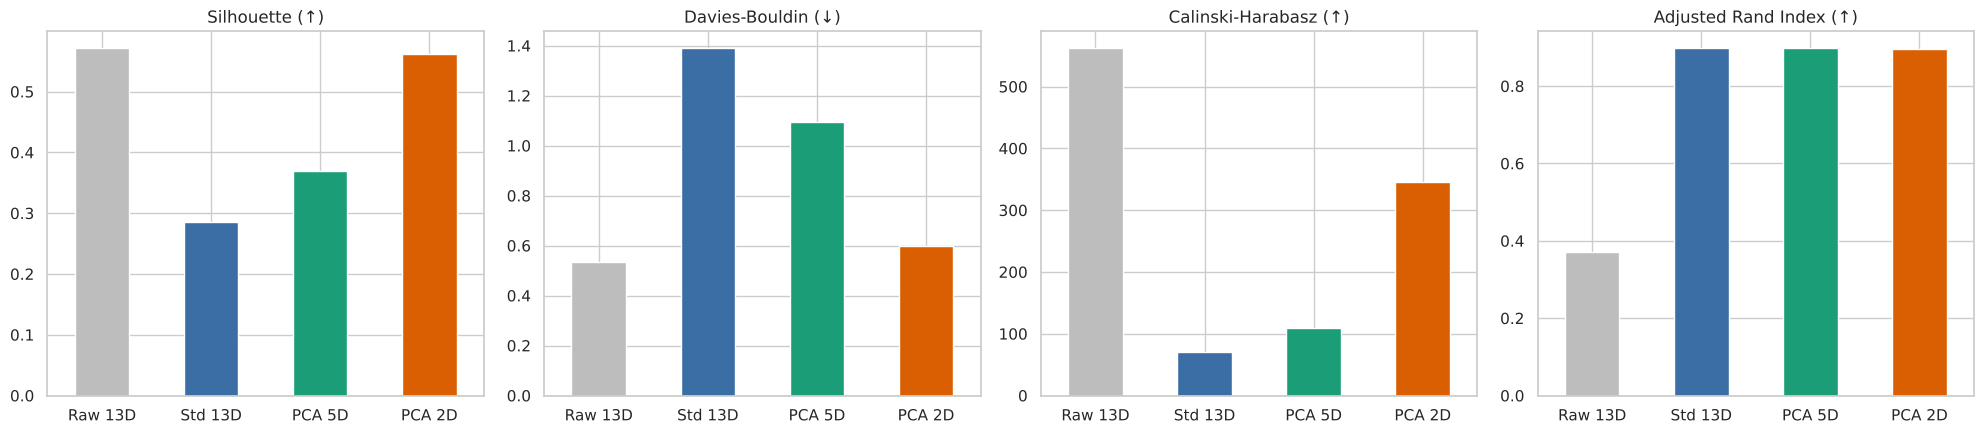

In [28]:
# Side-by-side bar charts of the metrics
metric_cols = ["Silhouette (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)", "Adjusted Rand Index (↑)"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
colors = ["#bdbdbd", "#3b6ea5", "#1b9e77", "#d95f02"]
for ax, m in zip(axes, metric_cols):
    comparison[m].plot(kind="bar", ax=ax, color=colors)
    ax.set_title(m); ax.set_xlabel("")
    ax.set_xticklabels(["Raw 13D", "Std 13D", "PCA 5D", "PCA 2D"], rotation=0)
plt.tight_layout(); plt.show()

In [29]:
# Agreement between the standardised-original and the PCA clusterings (ARI = 1 means identical partition)
print("ARI  (standardised 13D  vs  PCA 5D clusters):", round(adjusted_rand_score(labels_std, labels_pca), 3))
display(pd.crosstab(labels_std + 1, labels_pca + 1, rownames=["Std 13D cluster"], colnames=["PCA 5D cluster"]))

ARI  (standardised 13D  vs  PCA 5D clusters): 1.0


PCA 5D cluster,1,2,3
Std 13D cluster,,,
1,65,0,0
2,0,51,0
3,0,0,62


---
## Task 5: Comparison and Analysis
### 5.1 Sensitivity: how many components should the clustering use?
To reflect on the impact of dimensionality reduction, we cluster on the first *n* components for n = 2 … 13 (n = 13 is the full, rotated data and is equivalent to the standardised original data).

,Variance kept (%),Silhouette,Davies-Bouldin,ARI vs true Type
n_components,,,,
2,55.406,0.561,0.597,0.895
3,66.530,0.453,0.840,0.880
4,73.599,0.407,0.991,0.847
5,80.162,0.369,1.093,0.897
6,85.098,0.346,1.157,0.897
7,89.337,0.328,1.221,0.897
8,92.018,0.315,1.267,0.897
9,94.240,0.306,1.304,0.897
10,96.170,0.299,1.336,0.897


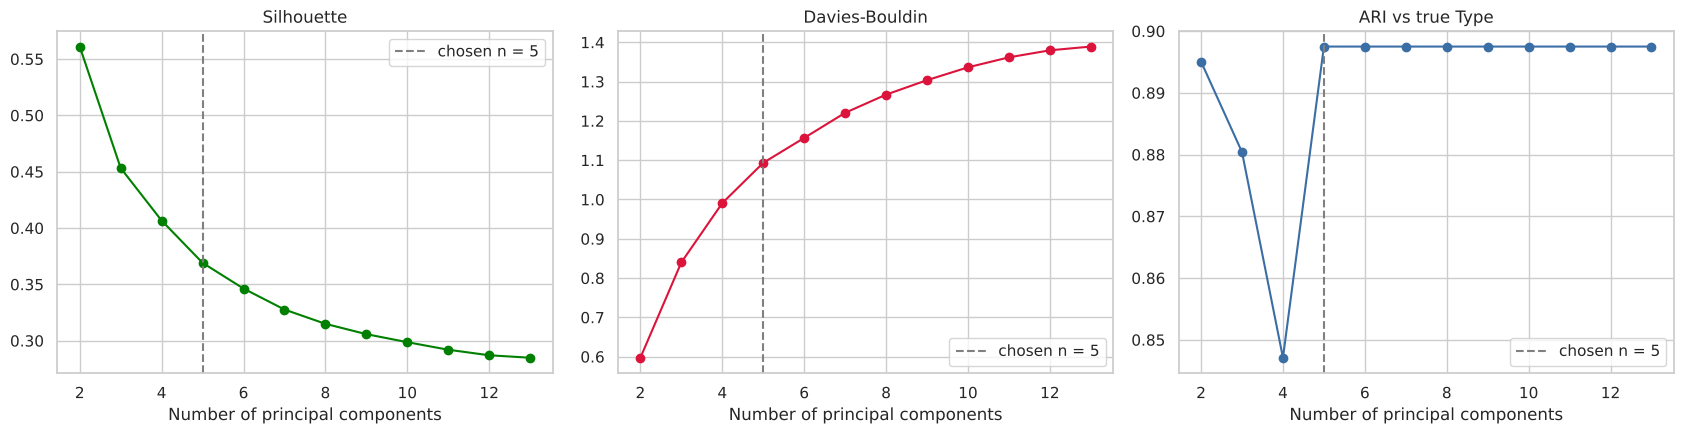

In [30]:
rows = []
for n in range(2, 14):
    Zn = PCA(n_components=n, random_state=RANDOM_STATE).fit_transform(X_scaled)
    lab, _, t = run_kmeans(Zn)
    rows.append({"n_components": n,
                 "Variance kept (%)": cum[n - 1] * 100,
                 "Silhouette": silhouette_score(Zn, lab),
                 "Davies-Bouldin": davies_bouldin_score(Zn, lab),
                 "ARI vs true Type": adjusted_rand_score(y, lab)})
sweep = pd.DataFrame(rows).set_index("n_components")
display(sweep.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, c in zip(axes, ["Silhouette", "Davies-Bouldin", "ARI vs true Type"], ["green", "crimson", "#3b6ea5"]):
    ax.plot(sweep.index, sweep[col], "o-", color=c)
    ax.axvline(N_COMPONENTS, color="gray", ls="--", label=f"chosen n = {N_COMPONENTS}")
    ax.set_xlabel("Number of principal components"); ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

### 5.2 Similarities and differences
**Similarities**
- Clustering on the standardised original data and on the 5-PC data gives the **identical partition** (ARI = 1.0 between them; not a single wine changes cluster), so both agree equally well with the true cultivars (ARI ≈ 0.90, NMI ≈ 0.88). Both mis-assign the same 6 wines (3 Type-2 wines grouped with Type 3 and 3 with Type 1).
- This shows that the 8 discarded components (~20 % of the variance) contained mostly noise/redundancy, not cluster structure.

**Differences**
- **Internal metrics improve as dimensions are removed.** The silhouette rises from 0.285 (13D) → 0.369 (5D) → 0.561 (2D) and Davies-Bouldin falls from 1.39 → 1.09 → 0.60. This is expected: distances in high dimensions are diluted by noisy features ("curse of dimensionality"), and PCA keeps the high-variance directions where the clusters are separated.
- **External agreement does not keep improving.** ARI is flat (0.897) for 5–13 PCs and varies only between 0.85 and 0.90 for fewer components (0.895 with 2 PCs, 0.880 with 3, 0.847 with 4). Better internal scores therefore do **not** mean better clusters – they partly reflect the lower dimensionality of the space itself, so silhouette values from spaces of different dimension are not strictly comparable.
- **Raw vs. scaled:** scaling matters far more than PCA. Clustering unscaled data scores best on the internal metrics yet worst against the real cultivars (ARI ≈ 0.37).

### 5.3 Impact of dimensionality reduction on clustering performance
- It **did not hurt** cluster quality: with 62 % fewer dimensions (13 → 5) the cluster recovery stayed at ARI ≈ 0.90.
- It **improved cluster compactness/separation** as measured by silhouette, Davies-Bouldin and Calinski-Harabasz.
- It enabled meaningful **2-D visualisation** of the clusters, with only a small loss of accuracy (2 PCs still give ARI ≈ 0.90).
- It makes clustering **faster and lighter** (fewer dimensions to compute distances over). On this tiny dataset the time difference is negligible (milliseconds), but it would matter for large, high-dimensional data.

### 5.4 Trade-offs: PCA + clustering vs. clustering on the original features
| Aspect | Clustering on original (standardised) features | Clustering on PCA components |
|---|---|---|
| **Information** | Uses 100 % of the variance | Discards some variance (here 19.8 % with 5 PCs, 44.6 % with 2 PCs) |
| **Interpretability** | Each axis is a real chemical measurement; centroids are directly readable | Axes are linear mixtures of features; need loadings to interpret |
| **Noise / redundancy** | Correlated and noisy features all influence distances | Correlated features are merged and low-variance noise is dropped |
| **Computation** | Slower in high dimensions; extra PCA step is not needed | Faster clustering, but requires an additional PCA step |
| **Visualisation** | Hard beyond 3 features | Natural 2-D/3-D plots |
| **Risk** | Curse of dimensionality | Low-variance directions can hold class-relevant information and would be lost; sensitive to scaling and outliers; only captures *linear* structure |

---
## Task 6: Conclusion and Insights
### 6.1 Key findings
1. **Data:** 178 wines × 13 clean numeric features, strongly correlated in a "phenolic" block (`Flavanoids`, `Phenols`, `Dilution`, `Proanthocyanins`), with features on very different scales.
2. **PCA:** The first 2 PCs explain 55.4 % of the variance, the first 3 explain 66.5 % (Kaiser criterion) and 5 PCs reach 80.2 %. The leading components have a clear chemical meaning (PC1 ≈ phenolic content, PC2 ≈ colour intensity / alcohol / proline).
3. **Scaling is crucial:** K-means on unscaled data is dominated by `Proline` and matches the true cultivars poorly (ARI ≈ 0.37), even though its internal metrics look excellent. After standardisation, ARI jumps to ≈ 0.90.
4. **PCA vs. original:** Clustering on 5 PCs reproduces the clustering of the 13 standardised features almost exactly (identical partition, ARI ≈ 0.90 against the true cultivars) while improving silhouette (0.285 → 0.369) and Davies-Bouldin (1.39 → 1.09). Even 2 PCs recover the cultivars well (ARI ≈ 0.90).
5. **Internal metrics can mislead:** the "best" internal scores came from the unscaled data (poor real agreement) and from very low-dimensional PCA spaces; external validation against known labels (ARI/NMI) gave the more reliable verdict.

### 6.2 Practical implications
- PCA is a cheap, effective pre-processing step for correlated, high-dimensional data: it reduces redundancy and noise, speeds up distance-based algorithms and makes data visualisable.
- Pre-processing choices (especially **feature scaling**) can influence results more than the choice of dimensionality reduction itself.
- Always combine internal metrics (silhouette, Davies-Bouldin) with domain knowledge or external labels when available, and compare quality across *similar* spaces.

### 6.3 Recommendations
| Situation | Recommendation |
|---|---|
| Features are on different scales | **Always standardise** before PCA and K-means. |
| Many correlated features, or dozens to thousands of dimensions | **Use PCA first** (keep ≈ 80–95 % variance, check with scree plot) and then cluster. |
| Need to visualise or explain cluster structure to others | Use the **first 2–3 PCs** for plotting (while clustering on more PCs if needed). |
| Few features (≈ 10–20), low redundancy, and interpretability of centroids in original units is required | **Cluster directly on the (scaled) original features** – little is gained from PCA. |
| Clusters may be non-linear or depend on low-variance directions | PCA may hide them; consider the original features or non-linear methods (t-SNE, UMAP, kernel PCA). |

### 6.4 Limitations & next steps
- Only K-means with k = 3 was studied; other algorithms (Gaussian mixtures, hierarchical, DBSCAN) could be compared.
- The dataset is small (178 samples), so the differences between settings are modest; results may vary with other data.
- Possible extensions: robust scaling, outlier treatment, stability analysis over many random seeds, and feature-selection alternatives to PCA.